# 05 - Bias Mitigation: Does Fixing the Predictions Change the Explanations?

We retrain **Logistic Regression** with fairlearn's **ExponentiatedGradient** under a **demographic-parity**
constraint on each dataset's primary sensitive attribute (Adult: sex, COMPAS: race), then compare
**before vs after** on:

* performance (accuracy, F1, ROC-AUC),
* fairness (demographic parity, equal opportunity) - for the constrained attribute *and* the other one,
* **LIME** explanations per group (reliance, rank agreement, fidelity) on the same instances as notebook 04.

**How ExponentiatedGradient works.** It repeatedly re-weights the training rows and refits a Logistic Regression,
pushing the groups' selection rates together. The result is a *randomised mixture* of Logistic Regressions:
for each person one member is drawn at random (by weight) to decide. The fairness guarantee holds for these
random predictions, so accuracy, F1 and fairness are measured on them (seeded, so reproducible).
ROC-AUC and LIME use the mixture's expected probability.

**Why only LIME?** The mixture is neither one tree model nor one linear model, so TreeExplainer and
LinearExplainer do not apply; LIME only needs `predict_proba`.

In [1]:
# --- Setup: works both in Google Colab and locally ---------------------------
# Colab: choose ONE way to get the project:
#   (a) USE_DRIVE = True  -> upload the fairness-xai folder to "My Drive"
#   (b) REPO_URL = "..."  -> clone it from GitHub
# Locally (Jupyter / VS Code) nothing needs changing.
import importlib.metadata
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = False
DRIVE_PROJECT = "/content/drive/MyDrive/fairness-xai"
REPO_URL = ""  # e.g. "https://github.com/<your-user>/fairness-xai.git"

if IN_COLAB:
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_ROOT = Path(DRIVE_PROJECT)
    elif REPO_URL:
        PROJECT_ROOT = Path("/content/fairness-xai")
        if not PROJECT_ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(PROJECT_ROOT)], check=True)
    else:
        raise RuntimeError("Set USE_DRIVE = True or REPO_URL so Colab can find the project.")
    # Install the pinned versions once. If Colab then asks to "Restart session",
    # click it and run this cell again - the install is skipped the second time.
    try:
        already = importlib.metadata.version("shap") == "0.48.0"
    except importlib.metadata.PackageNotFoundError:
        already = False
    if not already:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                        str(PROJECT_ROOT / "requirements.txt")], check=True)
else:
    # Locally the notebook runs from notebooks/, so the project root is its parent.
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\tarun\Desktop\Mini Project\fairness-xai


In [2]:
%matplotlib inline
import pandas as pd
from IPython.display import display

from src import config
from src.explain import QUICK_SETTINGS, ExplainSettings
from src.mitigation import plot_mitigation, run_mitigation
from src.models import model_path, train_all
from src.preprocess import prepare_dataset

config.setup_logging()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# QUICK = True: tiny LIME samples, results in results/quick/. QUICK = False reuses the cached LIME
# explanations of the original model written by `python -m src.run_all`.
QUICK = False
if QUICK:
    config.set_results_dir(config.PROJECT_ROOT / "results" / "quick")
SETTINGS, N_BOOT = (QUICK_SETTINGS, config.QUICK_N_BOOTSTRAP) if QUICK else (ExplainSettings(), config.N_BOOTSTRAP)

C:\Users\tarun\Desktop\Mini Project\fairness-xai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Run the mitigation (both datasets, both settings)

In [3]:
prepared = {}
for name in config.DATASETS:
    loaded, split = prepare_dataset(name, save=False)
    if not all(model_path(name, s, m).exists() for s in config.SETTINGS for m in config.MODEL_NAMES):
        train_all(split, loaded.metadata)
    prepared[name] = (loaded, split)

mitigation = run_mitigation(prepared, SETTINGS, N_BOOT)
cols = ["dataset", "setting", "attribute", "constrained_attribute", "stage", "accuracy", "f1", "roc_auc",
        "selection_rate_privileged", "selection_rate_unprivileged", "dp_difference", "dp_difference_thresholded",
        "eo_difference", "spearman_rho", "fidelity_gap"]
display(mitigation[cols].round(3))

14:58:51 | INFO    | src.data | Loaded Adult from OpenML via fairlearn (48842 rows).


14:58:51 | INFO    | src.data | Adult ready: 45222 rows, 12 features, positive rate 0.248.


14:58:51 | INFO    | src.data | COMPAS ready: 5278 rows, 8 features, positive rate 0.470.


14:58:52 | INFO    | src.mitigation | Mitigating adult | with_sensitive | constraint: demographic parity on sex


14:58:56 | INFO    | src.mitigation | Mitigator fitted: 2 Logistic Regressions in the mixture.


14:58:56 | INFO    | src.explain | Using cached explanations explanations_adult_with_sensitive_logistic_regression_s200_l100_n1000.csv


... (12 outputs left out)

14:59:11 | INFO    | src.explain | Using cached explanations explanations_compas_without_sensitive_logistic_regression_mitigated_s200_l100_n1000.csv


14:59:12 | INFO    | src.stats | 40 tests: 0 significant before and 0 after Holm correction (alpha 0.05).


14:59:12 | INFO    | src.mitigation | Wrote mitigation.csv (16 rows) and mitigation_tests.csv (40 rows).


,dataset,setting,attribute,constrained_attribute,stage,accuracy,f1,roc_auc,selection_rate_privileged,selection_rate_unprivileged,dp_difference,dp_difference_thresholded,eo_difference,spearman_rho,fidelity_gap
0,adult,with_sensitive,sex,sex,before,0.843,0.649,0.903,0.259,0.078,0.180,NaN,0.124,1.000,0.005
1,adult,with_sensitive,race,sex,before,0.843,0.649,0.903,0.212,0.124,0.088,NaN,0.062,0.993,0.005
2,adult,with_sensitive,sex,sex,after,0.829,0.590,0.721,0.168,0.171,0.003,0.007,0.334,1.000,0.002
3,adult,with_sensitive,race,sex,after,0.829,0.590,0.721,0.179,0.111,0.068,0.068,0.033,1.000,0.006
4,adult,without_sensitive,sex,sex,before,0.843,0.648,0.902,0.255,0.082,0.173,NaN,0.096,1.000,0.003
5,adult,without_sensitive,race,sex,before,0.843,0.648,0.902,0.210,0.131,0.079,NaN,0.034,1.000,0.006
6,adult,without_sensitive,sex,sex,after,0.827,0.576,0.717,0.158,0.161,0.002,0.013,0.305,1.000,-0.000
7,adult,without_sensitive,race,sex,after,0.827,0.576,0.717,0.167,0.114,0.052,0.056,0.006,1.000,-0.001
8,compas,with_sensitive,race,race,before,0.669,0.617,0.721,0.232,0.505,0.272,NaN,0.328,0.952,-0.041
9,compas,with_sensitive,sex,race,before,0.669,0.617,0.721,0.124,0.462,0.338,NaN,0.413,0.952,-0.037


`dp_difference_thresholded` is shown for transparency only: it thresholds the mixture's expected probability at
0.5, which always follows the member with the largest weight - a different model from the one fairlearn
optimised.

## 2. Before vs after, constrained attribute

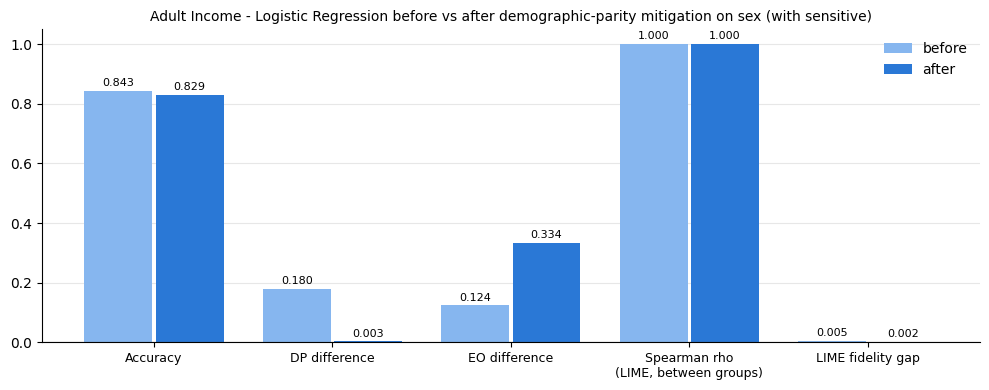

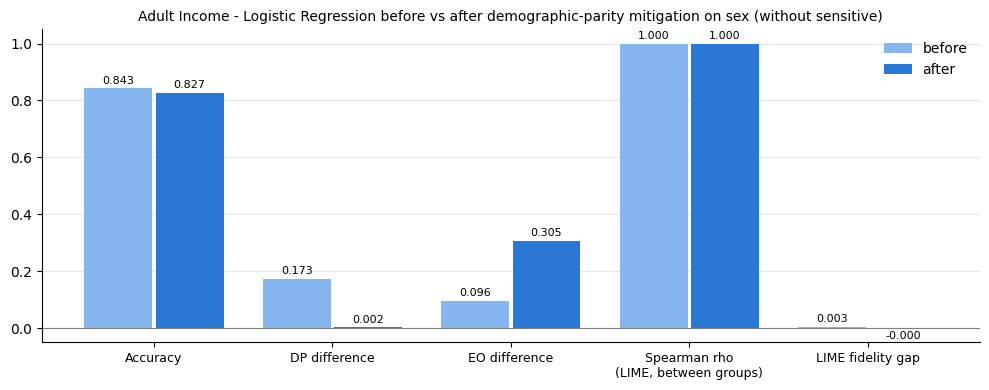

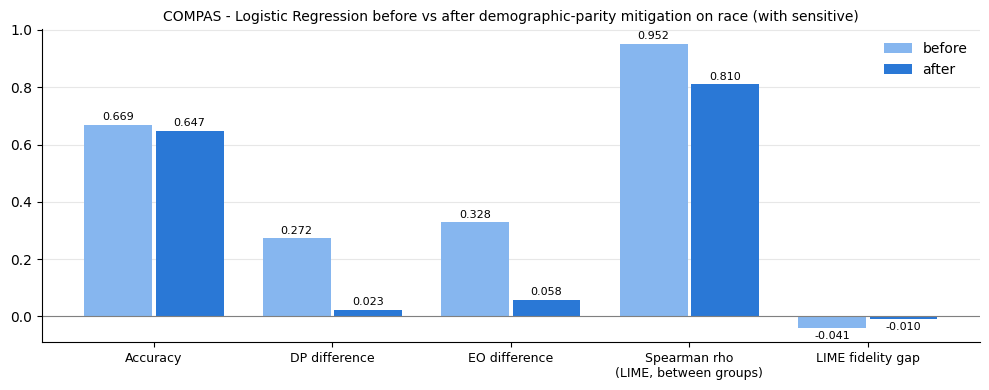

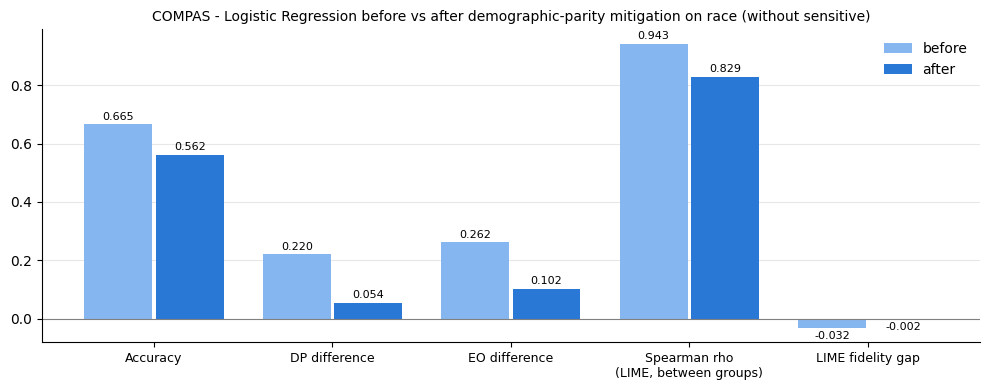

In [4]:
for name in config.DATASETS:
    for setting in config.SETTINGS:
        display(plot_mitigation(mitigation, name, setting))

## 3. What changed? (computed from the table above)

In [5]:
for (dataset, setting, attribute), part in mitigation.groupby(["dataset", "setting", "attribute"], sort=False):
    b = part[part["stage"] == "before"].iloc[0]
    a = part[part["stage"] == "after"].iloc[0]
    role = "constrained" if attribute == a["constrained_attribute"] else "NOT constrained"
    print(f"{config.DATASET_DISPLAY_NAMES[dataset]} | {setting} | {attribute} ({role}): "
          f"DP difference {b['dp_difference']:.3f} -> {a['dp_difference']:.3f}, "
          f"EO difference {b['eo_difference']:.3f} -> {a['eo_difference']:.3f}, "
          f"accuracy {b['accuracy']:.3f} -> {a['accuracy']:.3f}, "
          f"LIME rho between groups {b['spearman_rho']:.2f} -> {a['spearman_rho']:.2f}, "
          f"LIME fidelity gap {b['fidelity_gap']:+.3f} -> {a['fidelity_gap']:+.3f}")

Adult Income | with_sensitive | sex (constrained): DP difference 0.180 -> 0.003, EO difference 0.124 -> 0.334, accuracy 0.843 -> 0.829, LIME rho between groups 1.00 -> 1.00, LIME fidelity gap +0.005 -> +0.002
Adult Income | with_sensitive | race (NOT constrained): DP difference 0.088 -> 0.068, EO difference 0.062 -> 0.033, accuracy 0.843 -> 0.829, LIME rho between groups 0.99 -> 1.00, LIME fidelity gap +0.005 -> +0.006
Adult Income | without_sensitive | sex (constrained): DP difference 0.173 -> 0.002, EO difference 0.096 -> 0.305, accuracy 0.843 -> 0.827, LIME rho between groups 1.00 -> 1.00, LIME fidelity gap +0.003 -> -0.000
Adult Income | without_sensitive | race (NOT constrained): DP difference 0.079 -> 0.052, EO difference 0.034 -> 0.006, accuracy 0.843 -> 0.827, LIME rho between groups 1.00 -> 1.00, LIME fidelity gap +0.006 -> -0.001
COMPAS | with_sensitive | race (constrained): DP difference 0.272 -> 0.023, EO difference 0.328 -> 0.058, accuracy 0.669 -> 0.647, LIME rho between 

### Plain-English sentences (demographic parity), before and after

In [6]:
for row in mitigation[mitigation["attribute"] == mitigation["constrained_attribute"]].to_dict("records"):
    print(f"[{row['stage']:6s} | {row['dataset']} | {row['setting']}] {row['interpretation']}")

[before | adult | with_sensitive] Logistic Regression predicts >50K for 26% of men but 8% of women (demographic parity difference 0.18).
[after  | adult | with_sensitive] Logistic Regression (mitigated) predicts >50K for 17% of women and 17% of men (demographic parity difference 0.00).
[before | adult | without_sensitive] Logistic Regression predicts >50K for 26% of men but 8% of women (demographic parity difference 0.17).
[after  | adult | without_sensitive] Logistic Regression (mitigated) predicts >50K for 16% of women and 16% of men (demographic parity difference 0.00).
[before | compas | with_sensitive] Logistic Regression predicts re-offending within two years for 50% of African-American defendants but 23% of Caucasian defendants (demographic parity difference 0.27).
[after  | compas | with_sensitive] Logistic Regression (mitigated) predicts re-offending within two years for 40% of African-American defendants but 37% of Caucasian defendants (demographic parity difference 0.02).
[b

## 4. Do LIME explanations still differ between groups after mitigation?
Mann-Whitney U tests on per-instance reliance and fidelity, before and after, Holm-corrected together.

In [7]:
tests = pd.read_csv(config.table_path("mitigation_tests.csv"))
display(tests[["dataset", "setting", "model", "attribute", "measure", "mean_privileged", "mean_unprivileged",
               "p_value", "p_holm", "rank_biserial", "significant_holm"]].round(4))

,dataset,setting,model,attribute,measure,mean_privileged,mean_unprivileged,p_value,p_holm,rank_biserial,significant_holm
0,adult,with_sensitive,logistic_regression (before),sex,sensitive_reliance,0.0222,0.0224,0.7149,1.0,-0.0300,False
1,adult,with_sensitive,logistic_regression (before),sex,proxy_reliance,0.3537,0.3526,0.6663,1.0,0.0354,False
2,adult,with_sensitive,logistic_regression (before),sex,fidelity,0.7509,0.7456,0.2503,1.0,0.0942,False
3,adult,with_sensitive,logistic_regression (before),race,sensitive_reliance,0.0233,0.0222,0.0708,1.0,0.1480,False
4,adult,with_sensitive,logistic_regression (before),race,proxy_reliance,0.4246,0.4293,0.5229,1.0,-0.0524,False
5,adult,with_sensitive,logistic_regression (before),race,fidelity,0.7526,0.7480,0.4495,1.0,0.0620,False
6,adult,with_sensitive,logistic_regression (after),sex,sensitive_reliance,0.0289,0.0284,0.8402,1.0,0.0166,False
7,adult,with_sensitive,logistic_regression (after),sex,proxy_reliance,0.2963,0.2888,0.2251,1.0,0.0994,False
8,adult,with_sensitive,logistic_regression (after),sex,fidelity,0.5103,0.5088,0.8652,1.0,0.0140,False
9,adult,with_sensitive,logistic_regression (after),race,sensitive_reliance,0.0148,0.0140,0.2884,1.0,0.0870,False


## Summary
* Demographic-parity mitigation closes the selection-rate gap for the constrained attribute (section 3), at a cost
  in accuracy and ROC-AUC.
* Equal opportunity can move in the opposite direction: equalising *selection rates* is not the same as equalising
  *true positive rates* when base rates differ (see notebook 03).
* Sections 3 and 4 show whether the explanations' group differences change as well - fairer predictions do not
  automatically mean more similar explanations.